In [1]:
#Imports the libraries used for the RAM regression models.
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
#Loads the local DDR5 RAM dataset.
df = pd.read_csv('ddr5_ram_prices_raw_2026.csv')
print('Dataset:', df.shape)
print(df.columns.tolist())
df.head()

Dataset: (19705, 16)
['series_id', 'series_title', 'canonical_url', 'geography_type', 'geography_id', 'geography_label', 'observed_date', 'product_name', 'quantity_value', 'quantity_unit', 'quantity_name', 'price_amount', 'currency_code', 'normalized_price_amount', 'normalized_quantity_value', 'normalized_quantity_unit']


,series_id,series_title,canonical_url,geography_type,geography_id,geography_label,observed_date,product_name,quantity_value,quantity_unit,quantity_name,price_amount,currency_code,normalized_price_amount,normalized_quantity_value,normalized_quantity_unit
0,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-pri...,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-13,A-Tech 16GB DDR5 5600MHz PC5-44800 CL46 SODIMM...,16,gigabytes,16 gigabytes,230.93,USD,14.4331,1,gigabytes
1,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-pri...,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-13,Acer Predator Vesta II RGB DDR5 RAM 32GB (16GB...,32,gigabytes,32 gigabytes,437.99,USD,13.6872,1,gigabytes
2,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-pri...,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-13,Biwin Black Opal DW100 DDR5 RGB RAM 48GB (24GB...,48,gigabytes,48 gigabytes,529.99,USD,11.0415,1,gigabytes
3,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-pri...,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-13,CORSAIR Vengeance DDR5 RAM 16GB (2x8GB) Up to ...,16,gigabytes,16 gigabytes,234.99,USD,14.6869,1,gigabytes
4,ddr5_memory,DDR5 RAM,https://costinflation.com/indices/ddr5-ram-pri...,postal_code,11385,"New York, NY - Ridgewood/Glendale",2026-07-13,CORSAIR Vengeance DDR5 RAM 16GB (2x8GB) Up to ...,16,gigabytes,16 gigabytes,239.99,USD,14.9994,1,gigabytes


In [3]:
#Extracts numerical RAM specifications from each product name.
def get_number(name, pattern):
    match = re.search(pattern, str(name), re.IGNORECASE)
    return float(match.group(1)) if match else np.nan

data = df[['product_name', 'observed_date', 'quantity_value', 'price_amount']].copy()
data['capacity_gb'] = pd.to_numeric(data['quantity_value'], errors='coerce')
data['speed_mt_s'] = data['product_name'].apply(lambda s: get_number(s, r'\b(\d{4,5})\s*(?:MHz|MT/s|MTPS)\b'))
data['cas_latency'] = data['product_name'].apply(lambda s: get_number(s, r'\bCL\s*[-:]?\s*(\d{2})\b'))
data['sticks'] = data['product_name'].apply(lambda s: get_number(s, r'\b(\d+)\s*[xX]\s*\d+\s*GB\b'))
data['observed_date'] = pd.to_datetime(data['observed_date'], errors='coerce')
data['days'] = (data['observed_date'] - data['observed_date'].min()).dt.days
data['price_amount'] = pd.to_numeric(data['price_amount'], errors='coerce')
data = data.dropna(subset=['product_name', 'observed_date', 'capacity_gb', 'price_amount'])
data = data[(data['capacity_gb'] > 0) & (data['price_amount'] > 0)].drop_duplicates()

features = ['capacity_gb', 'speed_mt_s', 'cas_latency', 'sticks', 'days']
print('Usable rows:', len(data))
data[features + ['price_amount']].describe()

Usable rows: 2771


,capacity_gb,speed_mt_s,cas_latency,sticks,days,price_amount
count,2771.000000,2771.000000,2580.000000,2330.000000,2771.000000,2771.000000
mean,44.593288,5851.172862,35.814729,1.957082,13.596896,749.252025
std,41.591865,374.447216,5.397982,0.456670,8.324093,953.559729
min,8.000000,4800.000000,26.000000,1.000000,0.000000,109.990000
25%,32.000000,5600.000000,30.000000,2.000000,6.000000,379.990000
50%,32.000000,6000.000000,36.000000,2.000000,14.000000,469.990000
75%,64.000000,6000.000000,40.000000,2.000000,21.000000,769.950000
max,512.000000,8000.000000,60.000000,8.000000,28.000000,15908.960000


In [4]:
#Checks the relationship between RAM specifications and price.
print(data[features + ['price_amount']].corr()['price_amount'])

capacity_gb     0.963155
speed_mt_s      0.169715
cas_latency    -0.134873
sticks          0.697860
days           -0.000073
price_amount    1.000000
Name: price_amount, dtype: float64


In [5]:
#Splits the RAM products into training, validation, and testing data.
#The same product is kept in only one split.
split = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
a, b = next(split.split(data, groups=data['product_name']))
train = data.iloc[a]
other = data.iloc[b]

split = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
a, b = next(split.split(other, groups=other['product_name']))
val = other.iloc[a]
test = other.iloc[b]

print('Train:', len(train), 'Validation:', len(val), 'Test:', len(test))

Train: 1854 Validation: 360 Test: 557


In [6]:
#Converts the data into numerical inputs and target prices.
#Missing specifications use medians calculated from training data only.
medians = train[features].median().fillna(0)

def prepare(part):
    X = part[features].fillna(medians).to_numpy(dtype=np.float32)
    y = part[['price_amount']].to_numpy(dtype=np.float32)
    return X, y

X_train, y_train = prepare(train)
X_val, y_val = prepare(val)
X_test, y_test = prepare(test)

In [7]:
#Sets the training parameters and standardizes the inputs.
torch.manual_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
batch_size = 64
learning_rate = 0.001
N_Epochs = 120

x_mean = torch.tensor(X_train.mean(axis=0))
x_std = torch.tensor(X_train.std(axis=0) + 1e-6)
y_mean = float(y_train.mean())
y_std = float(y_train.std() + 1e-6)

train_ds = TensorDataset(torch.tensor(X_train), torch.tensor((y_train - y_mean) / y_std))
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
print('Device:', device)

Device: cpu


In [8]:
#Defines the PyTorch linear regression and neural network models.
class RegressionNet(nn.Module):
    def __init__(self, layers):
        super().__init__()
        self.register_buffer('mean', x_mean.clone())
        self.register_buffer('std', x_std.clone())
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net((x - self.mean) / self.std)

models = {
    'Linear Regression': RegressionNet([nn.Linear(5, 1)]),
    'MLP': RegressionNet([nn.Linear(5, 32), nn.ReLU(), nn.Linear(32, 1)]),
    'Deep MLP': RegressionNet([nn.Linear(5, 64), nn.ReLU(),
                               nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1)])
}

In [9]:
#Trains each model using MSE loss and the Adam optimizer.
def training_loop(model):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = nn.MSELoss()
    history = []

    for epoch in range(N_Epochs):
        model.train()
        losses = []
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        history.append(np.mean(losses))

    return model.cpu(), history

In [10]:
#Compares the models using validation R2 and RMSE.
def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X)).numpy() * y_std + y_mean

results = []
histories = {}

for name, model in models.items():
    model, history = training_loop(model)
    models[name] = model
    histories[name] = history
    prediction = predict(model, X_val)
    results.append([name, r2_score(y_val, prediction),
                    np.sqrt(mean_squared_error(y_val, prediction))])

results_df = pd.DataFrame(results, columns=['Model', 'R2', 'RMSE'])
results_df = results_df.sort_values('R2', ascending=False)
print(results_df.to_string(index=False))

            Model       R2       RMSE
              MLP 0.925602 275.072561
         Deep MLP 0.914807 294.352202
Linear Regression 0.834398 410.392286


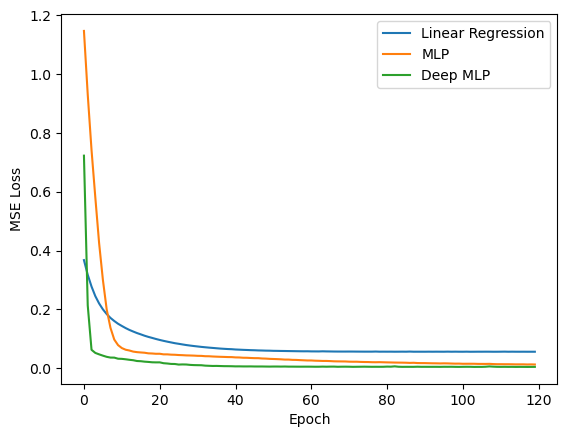

In [11]:
#Plots the training loss for all three models.
for name, history in histories.items():
    plt.plot(history, label=name)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

Best model: MLP
Test R2: 0.9448
Test RMSE: 97.36
Test MSE: 9479.07


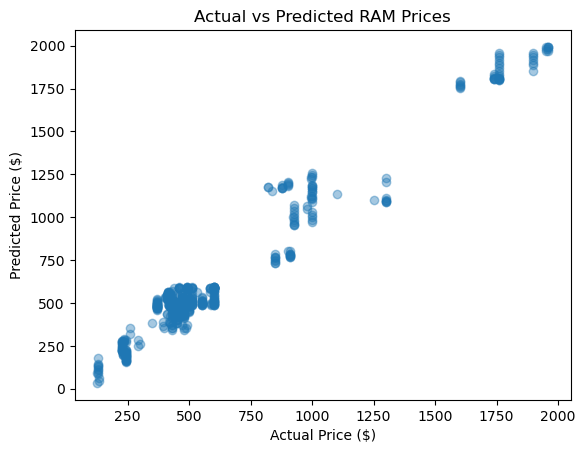

In [12]:
#Tests the best model on RAM products it has not seen before.
best_name = results_df.iloc[0]['Model']
best_model = models[best_name]
y_pred = predict(best_model, X_test)

print('Best model:', best_name)
print('Test R2:', round(r2_score(y_test, y_pred), 4))
print('Test RMSE:', round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print('Test MSE:', round(mean_squared_error(y_test, y_pred), 2))

plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs Predicted RAM Prices')
plt.show()

In [13]:
#Exports the best trained model to ONNX with prices returned in dollars.
class PriceInDollars(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.register_buffer('price_mean', torch.tensor(y_mean))
        self.register_buffer('price_std', torch.tensor(y_std))

    def forward(self, x):
        return self.model(x) * self.price_std + self.price_mean

onnx_model = PriceInDollars(best_model).eval()

torch.onnx.export(
    onnx_model,
    torch.zeros(1, len(features)),
    'ram_price_model.onnx',
    input_names=['input'],
    output_names=['price'],
    opset_version=15,
    external_data=False
)
print('Saved: ram_price_model.onnx')

W1116 00:54:43.550000 19672 site-packages\torch\onnx\_internal\exporter\_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 15 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W1116 00:54:44.395000 19672 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W1116 00:54:44.398000 19672 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W1116 00:54:44.400000 19672 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W1116 00:54:44.

[torch.onnx] Obtain model graph for `PriceInDollars([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `PriceInDollars([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 15).


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Saved: ram_price_model.onnx
